# Checkpoint 5: Narrative Analysis
This notebook makes every number and figure in the "Main Findings" section of the README.
Run it from top to bottom. It saves the figures in `figures/`.

## Setup and data (same cleaning as eda.ipynb)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams["font.size"] = 13
os.makedirs("figures", exist_ok=True)
rng = np.random.default_rng(418)   # fixed seed so the bootstrap numbers come out the same every time

In [2]:
twitter_daily = pd.read_csv("https://raw.githubusercontent.com/LazerLab/twitter-fake-news-replication/master/figure_1/data/daily_counts_exposures.csv")
twitter_sites = pd.read_csv("https://raw.githubusercontent.com/LazerLab/twitter-fake-news-replication/master/coexposure_network/data/total_exposure_counts.csv")
fake = pd.read_csv("https://raw.githubusercontent.com/KaiDMML/FakeNewsNet/master/dataset/politifact_fake.csv")
real = pd.read_csv("https://raw.githubusercontent.com/KaiDMML/FakeNewsNet/master/dataset/politifact_real.csv")
facebook = pd.read_csv("https://raw.githubusercontent.com/BuzzFeedNews/2016-10-facebook-fact-check/master/data/facebook-fact-check.csv")
ratings = pd.read_csv("https://raw.githubusercontent.com/hauselin/domain-quality-ratings/main/data/domain_pc1.csv")

In [3]:
# FakeNewsNet cleaning (same as eda.ipynb Section 2)
fake["label"] = "fake"
real["label"] = "real"
news = pd.concat([fake, real], ignore_index=True)
news["num_tweets"] = news["tweet_ids"].str.split().str.len()

dup_ids = news[news["id"].duplicated(keep=False)]["id"]
junk = news["title"].str.contains("Account Suspended|under construction|for sale|Outlook, Office, Skype", case=False)
news_clean = news[~news["id"].isin(dup_ids) & ~junk].copy()
news_clean["num_tweets"] = news_clean["num_tweets"].fillna(0)

# Twitter daily: date as datetime, percent instead of fraction
twitter_daily["date"] = pd.to_datetime(twitter_daily["date"])
twitter_daily = twitter_daily.sort_values("date")
twitter_daily["pct"] = twitter_daily["pct_fake"] * 100
twitter_daily["after"] = twitter_daily["ts_rel_days"] >= 0      # Nov 8 and later
twitter_daily["weekend"] = twitter_daily["date"].dt.dayofweek >= 5

# Twitter sites + quality ratings (same join as eda.ipynb Plot 3)
joined = twitter_sites.merge(ratings, left_on="website", right_on="domain")
joined["quality"] = pd.cut(joined["pc1"], bins=[0, 0.4, 0.7, 1], labels=["low", "medium", "high"], include_lowest=True)

print(news_clean.shape, twitter_daily.shape, joined.shape)

(1032, 6) (128, 13) (534, 5)


In [4]:
# helper functions
def boot_ci(a, b, stat, n=5000):
    """95% bootstrap confidence interval for stat(a) - stat(b)."""
    diffs = []
    for i in range(n):
        diffs.append(stat(rng.choice(a, len(a))) - stat(rng.choice(b, len(b))))
    return np.percentile(diffs, [2.5, 97.5])

def perm_test(a, b, stat, n=5000):
    """two-sided permutation test p-value for stat(a) - stat(b)."""
    observed = stat(a) - stat(b)
    pool = np.concatenate([a, b])
    count = 0
    for i in range(n):
        rng.shuffle(pool)
        if abs(stat(pool[:len(a)]) - stat(pool[len(a):])) >= abs(observed):
            count += 1
    return (count + 1) / (n + 1)

## Finding 1: the typical fake article was shared more than the typical real one (RQ1)

In [5]:
fk = news_clean[news_clean["label"] == "fake"]["num_tweets"].values
rl = news_clean[news_clean["label"] == "real"]["num_tweets"].values

print("median tweets  fake:", np.median(fk), " real:", np.median(rl))
print("mean tweets    fake:", round(fk.mean()), " real:", round(rl.mean()))
print("95% CI for median difference:", boot_ci(fk, rl, np.median))
print("permutation test p-value:", perm_test(fk.copy(), rl.copy(), np.median))

# chance a random fake article has more tweets than a random real one
both = pd.Series(np.concatenate([fk, rl])).rank().values
p_fake_higher = (both[:len(fk)].sum() - len(fk) * (len(fk) + 1) / 2) / (len(fk) * len(rl))
print("P(random fake > random real):", round(p_fake_higher, 2))

median tweets  fake: 76.0  real: 7.0
mean tweets    fake: 376  real: 643


95% CI for median difference: [49. 92.]


permutation test p-value: 0.0001999600079984003
P(random fake > random real): 0.64


In [6]:
# the most viral articles are real
for q in [0.5, 0.9, 0.95]:
    print(q, "quantile  fake:", round(np.quantile(fk, q)), " real:", round(np.quantile(rl, q)))

0.5 quantile  fake: 76  real: 7
0.9 quantile  fake: 745  real: 1537
0.95 quantile  fake: 1059  real: 2872


In [7]:
# CHECK 1: data quirk. Many more real articles have 0 tweets found.
print("share with 0 tweets  fake:", round((fk == 0).mean(), 2), " real:", round((rl == 0).mean(), 2))

fk1 = fk[fk > 0]
rl1 = rl[rl > 0]
print("only articles with at least 1 tweet -> median fake:", np.median(fk1), " real:", np.median(rl1))
print("95% CI for median difference:", boot_ci(fk1, rl1, np.median))

share with 0 tweets  fake: 0.09  real: 0.35
only articles with at least 1 tweet -> median fake: 99.0  real: 55.0


95% CI for median difference: [ 9.5 72. ]


In [8]:
# CHECK 2: does Facebook show the same thing? And is it just the type of page (confounder)?
fb = facebook.dropna(subset=["share_count"])
print(fb.groupby("Rating")["share_count"].median())
mf = fb[fb["Rating"] == "mostly false"]["share_count"].values
mt = fb[fb["Rating"] == "mostly true"]["share_count"].values
print("95% CI for median difference (mostly false - mostly true):", boot_ci(mf, mt, np.median))

# split by page type: left / right / mainstream
fb[fb["Rating"].isin(["mostly false", "mostly true"])].groupby(["Category", "Rating"])["share_count"].agg(["count", "median"])

Rating
mixture of true and false     615.0
mostly false                 1178.0
mostly true                    57.0
no factual content            593.0
Name: share_count, dtype: float64


95% CI for median difference (mostly false - mostly true): [ 535. 2286.]


count  median
Category   Rating                     
left       mostly false     21  4587.0
           mostly true     250  2295.5
mainstream mostly true    1067    32.0
right      mostly false     82  1019.0
           mostly true     316    91.5

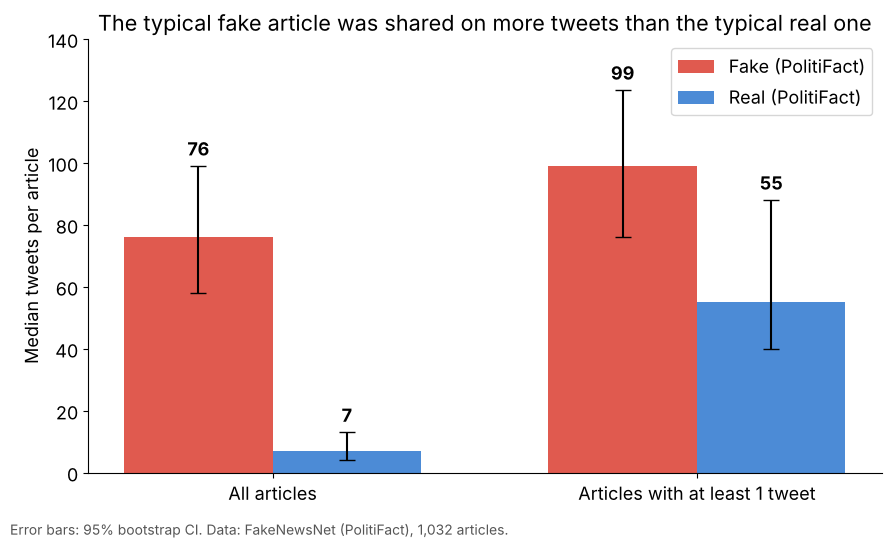

In [9]:
# Figure 1
groups = ["All articles", "Articles with at least 1 tweet"]
fake_meds = [np.median(fk), np.median(fk1)]
real_meds = [np.median(rl), np.median(rl1)]

def med_ci(a):
    b = [np.median(rng.choice(a, len(a))) for i in range(3000)]
    return np.percentile(b, [2.5, 97.5])

fake_err = np.array([med_ci(fk), med_ci(fk1)]).T
real_err = np.array([med_ci(rl), med_ci(rl1)]).T

x = np.arange(len(groups))
w = 0.35
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.bar(x - w/2, fake_meds, w, label="Fake (PolitiFact)", color="#E05A4F",
       yerr=[np.array(fake_meds) - fake_err[0], fake_err[1] - np.array(fake_meds)], capsize=6)
ax.bar(x + w/2, real_meds, w, label="Real (PolitiFact)", color="#4C8BD6",
       yerr=[np.array(real_meds) - real_err[0], real_err[1] - np.array(real_meds)], capsize=6)
for i in range(len(groups)):
    ax.text(x[i] - w/2, fake_err[1][i] + 2, int(fake_meds[i]), ha="center", va="bottom", weight="bold")
    ax.text(x[i] + w/2, real_err[1][i] + 2, int(real_meds[i]), ha="center", va="bottom", weight="bold")
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_ylabel("Median tweets per article")
ax.set_title("The typical fake article was shared on more tweets than the typical real one")
ax.set_ylim(0, 140)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Error bars: 95% bootstrap CI. Data: FakeNewsNet (PolitiFact), 1,032 articles.", fontsize=10, color="#555")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("figures/finding-1.png", dpi=200)
plt.show()

## Finding 2: the fake news share on Twitter was lower after Election Day (RQ2)

In [10]:
pre = twitter_daily[~twitter_daily["after"]]["pct"].values
post = twitter_daily[twitter_daily["after"]]["pct"].values

print("before (", len(pre), "days):", round(pre.mean(), 2), "%")
print("after  (", len(post), "days):", round(post.mean(), 2), "%")
print("difference:", round(pre.mean() - post.mean(), 2), "percentage points")
print("95% CI:", boot_ci(pre, post, np.mean))
print("permutation test p-value:", perm_test(pre.copy(), post.copy(), np.mean))

before ( 99 days): 5.58 %
after  ( 29 days): 3.9 %
difference: 1.68 percentage points
95% CI: [1.3200459  2.04343753]
permutation test p-value: 0.0001999600079984003


In [11]:
# CHECK 1: weekends have more fake news. Is the drop just a different mix of weekdays/weekends?
twitter_daily.groupby(["after", "weekend"])["pct"].agg(["mean", "count"])

mean  count
after weekend                 
False False    5.182725     71
      True     6.578193     28
True  False    3.542844     21
      True     4.843922      8

In [12]:
# CHECK 2: days next to each other are similar, so treat each WEEK as one data point
twitter_daily["week"] = twitter_daily["ts_rel_days"] // 7
weekly = twitter_daily.groupby("week").agg(pct=("pct", "mean"), after=("after", "min"))
wpre = weekly[~weekly["after"]]["pct"].values
wpost = weekly[weekly["after"]]["pct"].values
print("weeks before:", len(wpre), " weeks after:", len(wpost))
print("weekly means:", round(wpre.mean(), 2), "vs", round(wpost.mean(), 2))
print("95% CI:", boot_ci(wpre, wpost, np.mean))

weeks before: 15  weeks after: 5
weekly means: 5.54 vs 3.83


95% CI: [1.29880763 2.14699572]


In [13]:
# CHECK 3: is it just the huge news days right after the election? Drop Nov 8-10.
print("after, without Nov 8-10:", round(twitter_daily[twitter_daily["ts_rel_days"] > 2]["pct"].mean(), 2), "%")
print("correlation between total news volume (N) and pct fake:", round(twitter_daily["N"].corr(twitter_daily["pct"]), 2))

after, without Nov 8-10: 4.08 %
correlation between total news volume (N) and pct fake: -0.51


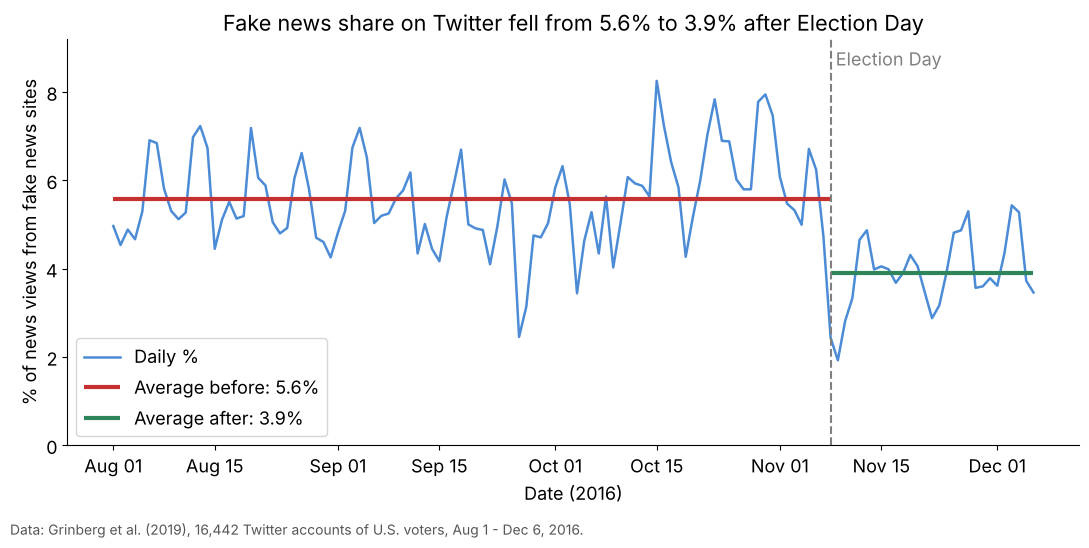

In [14]:
# Figure 2
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(twitter_daily["date"], twitter_daily["pct"], color="#4C8BD6", lw=1.8, label="Daily %")
e = pd.Timestamp("2016-11-08")
start = twitter_daily["date"].min()
end = twitter_daily["date"].max()
ax.hlines(pre.mean(), start, e, color="#C53030", lw=3, label=f"Average before: {pre.mean():.1f}%")
ax.hlines(post.mean(), e, end, color="#2F855A", lw=3, label=f"Average after: {post.mean():.1f}%")
ax.axvline(e, color="gray", ls="--")
ax.text(e, 8.6, " Election Day", color="gray")
ax.set_ylim(0, 9.2)
ax.set_ylabel("% of news views from fake news sites")
ax.set_xlabel("Date (2016)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_title("Fake news share on Twitter fell from 5.6% to 3.9% after Election Day")
ax.legend(loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Data: Grinberg et al. (2019), 16,442 Twitter accounts of U.S. voters, Aug 1 - Dec 6, 2016.", fontsize=10, color="#555")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("figures/finding-2.png", dpi=200)
plt.show()

## Finding 3: low-quality websites got a small share of Twitter views (RQ3)

In [15]:
summary = joined.groupby("quality", observed=True)["N"].agg(["count", "median", "sum"])
summary["share_of_sites_%"] = (summary["count"] / summary["count"].sum() * 100).round(1)
summary["share_of_views_%"] = (summary["sum"] / summary["sum"].sum() * 100).round(1)
summary

,count,median,sum,share_of_sites_%,share_of_views_%
quality,,,,,
low,155,5304.0,4821462,29.0,11.4
medium,183,10187.0,13422483,34.3,31.8
high,196,11184.5,23972667,36.7,56.8


In [16]:
# uncertainty: resample the websites and recompute the low-quality share of views
shares = []
for i in range(3000):
    s = joined.sample(len(joined), replace=True, random_state=int(rng.integers(1e9)))
    shares.append(s[s["quality"] == "low"]["N"].sum() / s["N"].sum() * 100)
print("low-quality share of views 95% CI:", np.percentile(shares, [2.5, 97.5]))

low = joined[joined["quality"] == "low"]["N"].values
high = joined[joined["quality"] == "high"]["N"].values
print("median views per site  high:", np.median(high), " low:", np.median(low))
print("95% CI for median difference:", boot_ci(high, low, np.median))

spearman = joined["pc1"].rank().corr(joined["N"].rank())
print("spearman correlation (quality vs views):", round(spearman, 2))

low-quality share of views 95% CI: [ 6.35124166 18.23772025]
median views per site  high: 11184.5  low: 5304.0
95% CI for median difference: [1140.1125 9503.15  ]
spearman correlation (quality vs views): 0.17


In [17]:
# CHECK 1: is it driven by a few giant sites? Drop the 10 most-viewed sites.
j2 = joined.sort_values("N", ascending=False).iloc[10:]
print("without top 10 sites -> low share:", round(j2[j2["quality"] == "low"]["N"].sum() / j2["N"].sum() * 100, 1), "%",
      " spearman:", round(j2["pc1"].rank().corr(j2["N"].rank()), 2))

# CHECK 2: does our 0.4 cutoff matter?
for cut in [0.3, 0.4, 0.5]:
    print("cutoff", cut, "-> low share:", round(joined[joined["pc1"] < cut]["N"].sum() / joined["N"].sum() * 100, 1), "%")

# CHECK 3: how concentrated are low-quality views?
low_sorted = joined[joined["quality"] == "low"].sort_values("N", ascending=False)
print("breitbart.com share of all low-quality views:", round(low_sorted["N"].iloc[0] / low_sorted["N"].sum() * 100, 1), "%")
print("top 10 low-quality sites share:", round(low_sorted["N"].head(10).sum() / low_sorted["N"].sum() * 100, 1), "%")

without top 10 sites -> low share: 15.1 %  spearman: 0.15
cutoff 0.3 -> low share: 8.6 %
cutoff 0.4 -> low share: 11.4 %
cutoff 0.5 -> low share: 15.5 %
breitbart.com share of all low-quality views: 20.8 %
top 10 low-quality sites share: 57.4 %


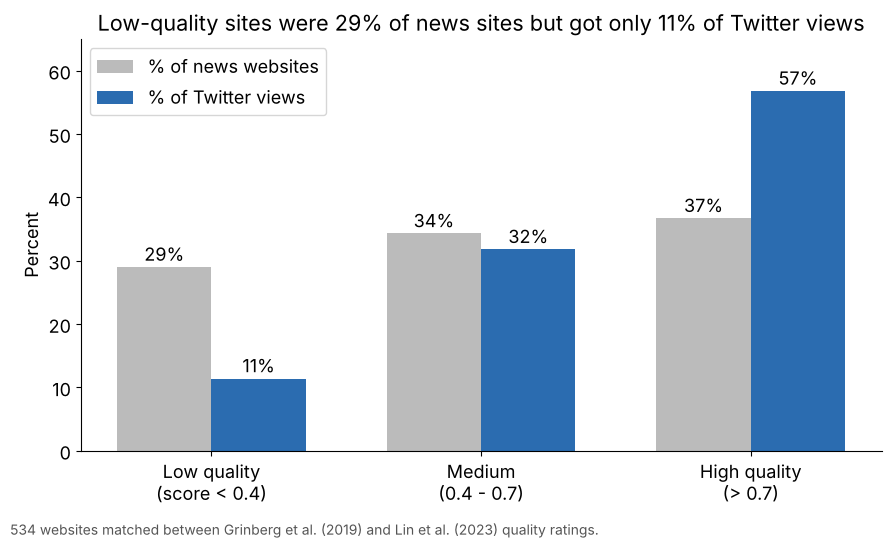

In [18]:
# Figure 3
groups = ["low", "medium", "high"]
x = np.arange(3)
w = 0.35
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.bar(x - w/2, summary.loc[groups, "share_of_sites_%"], w, label="% of news websites", color="#BBBBBB")
ax.bar(x + w/2, summary.loc[groups, "share_of_views_%"], w, label="% of Twitter views", color="#2B6CB0")
for i, g in enumerate(groups):
    ax.text(x[i] - w/2, summary.loc[g, "share_of_sites_%"] + 1, f"{summary.loc[g, 'share_of_sites_%']:.0f}%", ha="center")
    ax.text(x[i] + w/2, summary.loc[g, "share_of_views_%"] + 1, f"{summary.loc[g, 'share_of_views_%']:.0f}%", ha="center")
ax.set_xticks(x)
ax.set_xticklabels(["Low quality\n(score < 0.4)", "Medium\n(0.4 - 0.7)", "High quality\n(> 0.7)"])
ax.set_ylabel("Percent")
ax.set_ylim(0, 65)
ax.set_title("Low-quality sites were 29% of news sites but got only 11% of Twitter views")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "534 websites matched between Grinberg et al. (2019) and Lin et al. (2023) quality ratings.", fontsize=10, color="#555")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("figures/finding-3.png", dpi=200)
plt.show()